# 循環神經網路比較：SimpleRNN、GRU、LSTM 預測航空旅客數

簡報提到 Keras 內建三種循環層：`SimpleRNN`、`GRU`、`LSTM`。這份筆記本用**同一份資料、同一個網路結構**，只換循環層，比較三者的預測誤差。

| 段 | 內容 | 重點 |
|---|---|---|
| 1 | 環境與資料 | 讀入 1949–1960 年每月國際航線旅客數，共 144 筆 |
| 2 | 畫出序列 | 看趨勢與 12 個月的季節性 |
| 3 | 依時間切分與標準化 | 最後 24 個月當測試集，不打亂；縮放器只用訓練集配適 |
| 4 | 滑動視窗 | 用前 12 個月預測下一個月 |
| 5 | 建立三個模型 | 結構相同，只換循環層；核對參數量 |
| 6 | 訓練 | 固定亂數種子 |
| 7 | 評估 | 測試集均方根誤差 RMSE，並與季節性單純預測法比較 |
| 8 | 想一想 | |

**執行方式**：由上往下逐格執行，或「執行階段 → 全部執行」。資料很小，用 CPU 幾分鐘內可跑完，不必開 GPU。
本筆記本使用 Colab 內建的 Keras 3，不需要另外安裝套件。

## 1. 環境與資料

In [1]:
import os
import time
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers
from sklearn.preprocessing import MinMaxScaler

T0 = time.time()   # 最後用來算整份筆記本的執行時間
print('TensorFlow', tf.__version__, '| Keras', keras.__version__)
assert keras.__version__.startswith('3'), '這份筆記本要用 Keras 3'

CSV = 'airline-passengers.csv'
URL = ('https://raw.githubusercontent.com/pychang-ai/115-1_DLMA/main/'
       'topics/lstm-rnn/airline-passengers.csv')
if not os.path.exists(CSV):          # Colab 上沒有檔案時自動下載，不必手動上傳
    urllib.request.urlretrieve(URL, CSV)

df = pd.read_csv(CSV, parse_dates=['Month'], index_col='Month')
series = df['Passengers'].to_numpy(dtype='float32')   # 單位：千人
assert len(series) == 144, len(series)
print('筆數', len(series), '| 期間', df.index[0].strftime('%Y-%m'), '至', df.index[-1].strftime('%Y-%m'))
df.head()

TensorFlow 2.21.0 | Keras 3.15.1
筆數 144 | 期間 1949-01 至 1960-12


,Passengers
Month,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121


## 2. 畫出序列

先看資料長什麼樣子。這條序列有兩個特徵：逐年上升的**趨勢**，以及每 12 個月重複一次的**季節性**，夏季是高峰，而且高峰的幅度逐年變大。

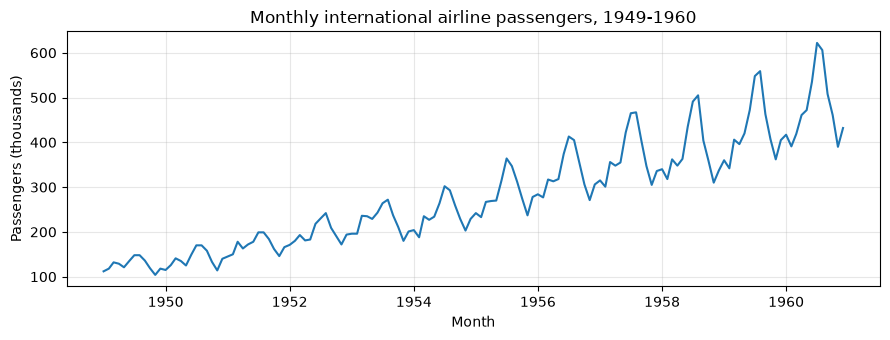

In [2]:
plt.figure(figsize=(9, 3.5))
plt.plot(df.index, series, color='tab:blue')
plt.title('Monthly international airline passengers, 1949-1960')
plt.xlabel('Month')
plt.ylabel('Passengers (thousands)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 3. 依時間切分與標準化

時間序列**不能隨機打亂**再切分：預測是用過去推未來，如果測試集的月份夾在訓練集中間，模型等於偷看了未來。這裡把最後 24 個月，也就是 1959 與 1960 兩年，留作測試集，前面 120 個月當訓練集。

神經網路對輸入的數值大小敏感，所以用 `MinMaxScaler` 把數值縮放到 0 與 1 之間。縮放器**只用訓練集配適**，再套用到測試集；如果用全部資料配適，測試集的最大值就洩漏給訓練過程了，這叫資料洩漏 data leakage。

因為旅客數逐年上升，測試集縮放後會**超過 1**，模型必須預測訓練時沒看過的數值範圍，這正是這份資料困難的地方。

In [3]:
N_TEST = 24                    # 最後 24 個月當測試集
LOOK_BACK = 12                 # 用前 12 個月預測下一個月
n_train = len(series) - N_TEST

train_raw = series[:n_train]
test_raw = series[n_train:]

scaler = MinMaxScaler()
scaler.fit(train_raw.reshape(-1, 1))                     # 只用訓練集配適
scaled = scaler.transform(series.reshape(-1, 1)).ravel().astype('float32')

# 核對：縮放器的最大最小值來自訓練集，不是全部資料
assert scaler.data_max_[0] == train_raw.max() and scaler.data_min_[0] == train_raw.min()
assert scaler.data_max_[0] < series.max(), '測試集有比訓練集更大的值，縮放後會超過 1'
print('訓練集', n_train, '個月，測試集', N_TEST, '個月')
print('訓練集縮放後範圍 %.2f 至 %.2f' % (scaled[:n_train].min(), scaled[:n_train].max()))
print('測試集縮放後範圍 %.2f 至 %.2f' % (scaled[n_train:].min(), scaled[n_train:].max()))

訓練集 120 個月，測試集 24 個月
訓練集縮放後範圍 0.00 至 1.00
測試集縮放後範圍 0.59 至 1.29


## 4. 滑動視窗

循環層的輸入形狀是「樣本數、時間步數、特徵數」。把序列切成一個個長度 12 的視窗：前 12 個月是輸入 X，第 13 個月是目標 y，然後視窗往後滑一個月。

測試集每個月的預測，輸入是它**前 12 個月的實際值**，所以這是一步預測 one-step-ahead forecast。測試集的目標月份完全不會出現在訓練樣本的目標裡。

In [4]:
def make_windows(values, first_target, last_target, look_back):
    # 目標位置從 first_target 到 last_target-1，輸入是目標前 look_back 個值
    X, y = [], []
    for t in range(first_target, last_target):
        X.append(values[t - look_back:t])
        y.append(values[t])
    X = np.array(X, dtype='float32')[..., np.newaxis]     # 加上特徵維度
    return X, np.array(y, dtype='float32')

X_train, y_train = make_windows(scaled, LOOK_BACK, n_train, LOOK_BACK)
X_test, y_test = make_windows(scaled, n_train, len(scaled), LOOK_BACK)

assert X_train.shape == (n_train - LOOK_BACK, LOOK_BACK, 1), X_train.shape
assert X_test.shape == (N_TEST, LOOK_BACK, 1), X_test.shape
print('X_train', X_train.shape, 'y_train', y_train.shape)
print('X_test ', X_test.shape, 'y_test ', y_test.shape)

X_train (108, 12, 1) y_train (108,)
X_test  (24, 12, 1) y_test  (24,)


## 5. 建立三個模型

三個模型的結構完全相同：輸入 → 一層 32 個單元的循環層 → 一個輸出的全連接層。唯一的差別是循環層的種類。

- **簡單循環神經網路 Simple Recurrent Neural Network（SimpleRNN）**：隱藏狀態每一步都被整個改寫，序列一長，早期資訊容易消失。
- **長短期記憶 Long Short-Term Memory（LSTM）**：多一條記憶單元 cell state，由輸入閘 input gate、遺忘閘 forget gate、輸出閘 output gate 決定要寫入、保留、輸出多少。
- **門控循環單元 Gated Recurrent Unit（GRU）**：把 LSTM 簡化成更新閘 update gate 與重設閘 reset gate，沒有獨立的記憶單元。

**核對參數量**：輸入 1 維、32 個單元時，SimpleRNN 的一組權重是 32×(1+32)+32 = 1,088 個。LSTM 有三個閘加一組候選值，共四組，所以是 4×1,088 = 4,352。Keras 的 GRU 有三組，且每組多一份偏差，是 3×(1,088+32) = 3,360。參數量本身就看得出閘的數目。

In [5]:
UNITS = 32
SEED = 42

def build_model(rnn_layer):
    keras.utils.set_random_seed(SEED)          # 固定亂數種子，三個模型起點條件一致
    model = keras.Sequential([
        keras.Input(shape=(LOOK_BACK, 1)),
        rnn_layer(UNITS),                      # 只有這一層不同
        layers.Dense(1),
    ])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss='mse')
    return model

RNN_LAYERS = {'SimpleRNN': layers.SimpleRNN, 'GRU': layers.GRU, 'LSTM': layers.LSTM}
EXPECTED = {'SimpleRNN': 1088, 'GRU': 3360, 'LSTM': 4352}

models = {}
for name, layer in RNN_LAYERS.items():
    models[name] = build_model(layer)
    n_rnn = models[name].layers[0].count_params()
    assert n_rnn == EXPECTED[name], (name, n_rnn)
    print('%-9s 循環層參數 %5d，全部參數 %5d' % (name, n_rnn, models[name].count_params()))

SimpleRNN 循環層參數  1088，全部參數  1121


GRU       循環層參數  3360，全部參數  3393
LSTM      循環層參數  4352，全部參數  4385


## 6. 訓練

三個模型用相同的設定訓練：200 個回合 epoch、批次大小 16、Adam 最佳化器、均方誤差損失。訓練樣本只有 108 筆，所以很快。

`shuffle=True` 打亂的是**訓練視窗的順序**，每個視窗內部的時間順序不變，也沒有動到測試集，所以不違反前面依時間切分的原則。

SimpleRNN 訓練  21.6 秒，最後的訓練損失 0.00092


GRU       訓練  22.9 秒，最後的訓練損失 0.00193


LSTM      訓練  27.7 秒，最後的訓練損失 0.00185


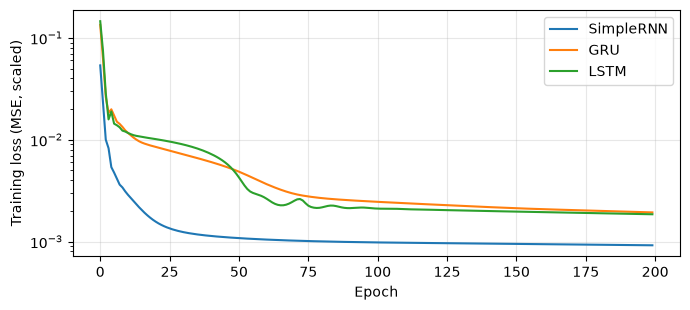

In [6]:
EPOCHS = 200
BATCH = 16

histories, train_seconds = {}, {}
for name, model in models.items():
    keras.utils.set_random_seed(SEED)          # 讓打亂順序也可重現
    t = time.time()
    histories[name] = model.fit(X_train, y_train, epochs=EPOCHS, batch_size=BATCH,
                                shuffle=True, verbose=0)
    train_seconds[name] = time.time() - t
    print('%-9s 訓練 %5.1f 秒，最後的訓練損失 %.5f'
          % (name, train_seconds[name], histories[name].history['loss'][-1]))

plt.figure(figsize=(7, 3.2))
for name, h in histories.items():
    plt.plot(h.history['loss'], label=name)
plt.yscale('log')
plt.xlabel('Epoch')
plt.ylabel('Training loss (MSE, scaled)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 7. 評估

把預測值還原成原始單位，也就是千人，再算測試集 24 個月的均方根誤差 Root Mean Square Error（RMSE），數值越小越好。

只比三個模型還不夠，還要有一個**不必訓練的基準**。這裡用季節性單純預測法 seasonal naive method：直接拿 12 個月前的實際值當預測。如果神經網路贏不了這麼簡單的方法，就不能說它學到了有用的東西。

In [7]:
def rmse(actual, predicted):
    return float(np.sqrt(np.mean((np.asarray(actual) - np.asarray(predicted)) ** 2)))

actual = test_raw                                        # 測試集實際值，原始單位
preds = {}
for name, model in models.items():
    p = model.predict(X_test, verbose=0)
    preds[name] = scaler.inverse_transform(p).ravel()    # 還原成千人

naive = series[n_train - 12:len(series) - 12]            # 12 個月前的實際值
assert len(naive) == N_TEST and np.allclose(scaler.inverse_transform(
    y_test.reshape(-1, 1)).ravel(), actual, atol=1e-2)   # 核對：還原後的目標就是實際值

rmse_naive = rmse(actual, naive)
rows = [{'模型': '季節性單純預測法（基準）', '循環層參數量': 0, '訓練秒數': 0.0,
         '測試 RMSE（千人）': rmse_naive}]
for name in models:
    rows.append({'模型': name, '循環層參數量': EXPECTED[name], '訓練秒數': round(train_seconds[name], 1),
                 '測試 RMSE（千人）': rmse(actual, preds[name])})
results = pd.DataFrame(rows)
results['相對基準'] = (results['測試 RMSE（千人）'] / rmse_naive - 1).map('{:+.1%}'.format)
results['贏過基準'] = ['—'] + ['是' if r < rmse_naive else '否' for r in results['測試 RMSE（千人）'][1:]]
results['測試 RMSE（千人）'] = results['測試 RMSE（千人）'].round(2)
results

,模型,循環層參數量,訓練秒數,測試 RMSE（千人）,相對基準,贏過基準
0,季節性單純預測法（基準）,0,0.0,49.99,+0.0%,—
1,SimpleRNN,1088,21.6,43.18,-13.6%,是
2,GRU,3360,22.9,50.93,+1.9%,否
3,LSTM,4352,27.7,68.40,+36.8%,否


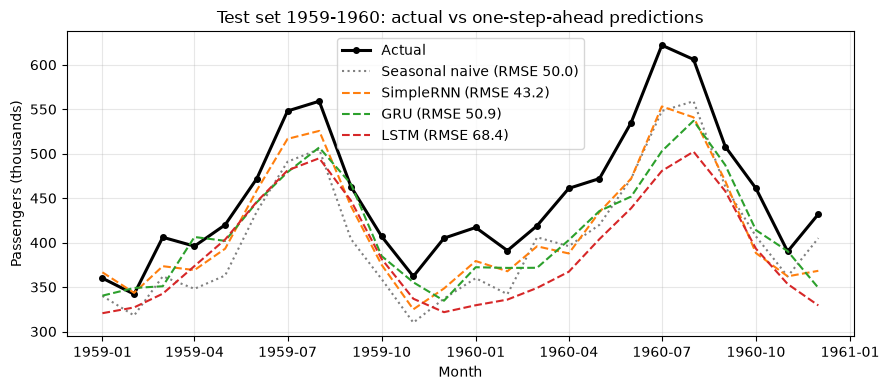

這一次執行誤差最小的循環模型： SimpleRNN
沒有贏過基準的模型： GRU、LSTM
整份筆記本執行時間 76 秒


In [8]:
test_index = df.index[n_train:]
plt.figure(figsize=(9, 4))
plt.plot(test_index, actual, color='black', linewidth=2.2, marker='o', markersize=4, label='Actual')
plt.plot(test_index, naive, color='gray', linestyle=':', label='Seasonal naive (RMSE %.1f)' % rmse_naive)
for name, color in zip(models, ['tab:orange', 'tab:green', 'tab:red']):
    plt.plot(test_index, preds[name], color=color, linestyle='--',
             label='%s (RMSE %.1f)' % (name, rmse(actual, preds[name])))
plt.title('Test set 1959-1960: actual vs one-step-ahead predictions')
plt.xlabel('Month')
plt.ylabel('Passengers (thousands)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

best = min(models, key=lambda n: rmse(actual, preds[n]))
losers = [n for n in models if rmse(actual, preds[n]) >= rmse_naive]
print('這一次執行誤差最小的循環模型：', best)
print('沒有贏過基準的模型：', '、'.join(losers) if losers else '無')
print('整份筆記本執行時間 %.0f 秒' % (time.time() - T0))

### 怎麼讀這個結果

- 上面的表與圖是**這一次執行**的結果。換一個亂數種子、換一台機器或換 Keras 版本，數字會有些不同，名次也可能互換；資料只有 144 筆，一次執行的名次不能當成定論。
- 「贏過基準」那一欄如果出現「否」，請照實記錄，不要只報好看的那個模型。這份資料的趨勢是逐年上升，測試集的數值超出訓練範圍，循環層不一定處理得好。
- LSTM 與 GRU 的閘是為了長序列設計的。這裡的視窗只有 12 步，SimpleRNN 還記得住，所以閘的優勢不一定顯現。

## 8. 想一想

1. 第 3 段為什麼要依時間切分，而不用 `train_test_split` 隨機切？如果縮放器改用全部 144 筆配適，測試 RMSE 會變好還是變差，這個數字還可信嗎？
2. 這份資料每 12 個月重複一次。LSTM 的遺忘閘在這裡要做什麼事：哪些資訊值得一路保留到第 12 步，哪些可以丟掉？把 `LOOK_BACK` 改成 3 或 24 再跑一次，三個模型的差距怎麼變？
3. 把 `SEED` 改成其他數字跑三次，三個模型的名次穩定嗎？要怎麼報告結果，才不會被單一次執行誤導？